
# 08 波动率交易：核心笔记

> **这本书要解决的问题**：期权价格里唯一看不清的东西是波动率。怎么把价格翻译成波动率、怎么估计和预测波动率、怎么用波动率而不是方向表达观点、怎么对冲、怎么下注？Euan Sinclair 的《Volatility Trading》讲的就是这一整套。

## 本章导读

这是一本 **0 基础可读** 的核心笔记，对应 Sinclair《Volatility Trading》（2nd ed., Wiley, 2013）。全书只抓一条主线：

1. **模型只是翻译工具**：BSM 与其假设，用波动率而不是方向表达观点；
2. **波动率怎么量**：close-to-close、Parkinson、Garman–Klass、Rogers–Satchell、Yang–Zhang，偏差、效率与微观结构噪声；
3. **波动率的风格事实与预测**：聚集、均值回归、季节性；EWMA、GARCH、波动率锥、方差溢价；
4. **隐含波动率的动态**：水平、skew、期限结构，以及 skew 的五个来源；
5. **对冲**：ad hoc 与 utility-based、交易成本、离散对冲的 PnL 分布；
6. **资金管理与评价**：Kelly、固定比例、破产风险；Sharpe/Calmar/Sortino/K-ratio/Omega 与持续性；
7. **其他**：心理偏差、VIX/VIX 期货/ETN、杠杆 ETF，以及一笔交易的完整生命周期。

代码全部用**合成数据**（教学示例），只演示方法，不代表真实市场；不联网。

### 学习目标

- 能写出 BSM 的假设，并说清“价格 ↔ 隐含波动率”只是翻译，不是预测。
- 能用五种估计器算历史波动率，并说清各自的偏差、效率与噪声敏感性。
- 能说出波动率聚集、均值回归、季节性、杠杆效应，并用 EWMA/GARCH 做预测。
- 能读波动率锥和方差溢价，理解“IV 平均高于 RV”为什么是保险费的形状。
- 能说出 skew 的五个来源，区分水平、斜率、曲率、期限结构的变化。
- 能对比“不 hedge / 离散 delta hedge / 带成本 hedge”的 PnL 分布与路径依赖。
- 能用 Kelly 与破产概率解释“为什么不要满仓”，并用 5 个指标评价交易。
- 能描述一笔波动率交易从 pre-trade 到 post-trade 的完整流程。

### 先修

零基础即可：会加减乘除、知道“标准差”的大意。期权、Greeks、随机过程会在用到时用大白话解释。

---

### 环境准备



In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：波动率交易员、期权做市、结构化产品、风险与组合管理。
- **输入**：期权报价/隐含波动率、标的价格与 OHLC、成交量、利率与到期结构。
- **输出**：波动率估计与预测、IV 相对贵贱的判断、对冲方案、仓位与评价。
- **在流程的哪一步**：从“看方向”升级到“看波动率与尾部”的核心环节。
- **失败模式**：把 BSM 当真理、用错波动率估计器、只看 IV 不看 RV、忽略对冲成本与路径、满仓下注。
- **最小工作流**：选标的与期限 → 估/预测 RV → 比较 IV 与 RV → 选工具（期权/跨式/方差）→ 对冲 → 评价与复盘。

---

## 1. 模型只是翻译工具：BSM 与隐含波动率

### 1.1 BSM 的假设

Black–Scholes–Merton 模型假设：标的价格服从几何布朗运动、波动率恒定、无跳跃、可连续无成本交易、无套利、利率恒定。结论是欧式看涨价格

$$C=S\Phi(d_1)-Ke^{-rT}\Phi(d_2),\qquad
d_1=\frac{\ln(S/K)+(r+\frac12\sigma^2)T}{\sigma\sqrt T},\quad d_2=d_1-\sigma\sqrt T.$$

假设几乎都不成立：波动率会变、会跳、交易有成本。那为什么还用？因为它把“价格”翻译成“波动率”，让不同行权价、不同期限的期权可以比较。**模型不是真理，是语言。**

### 1.2 用波动率而不是方向表达观点

- 看涨方向：买看涨、买期货；
- 看波动率：买跨式/宽跨式（做多波动率）、卖跨式（做空波动率）、方差互换；
- 看相对价值：买近月 IV、卖远月 IV（期限结构），或买 skew、卖水平。

波动率交易的核心是：**你交易的是“实际波动会比隐含波动大还是小”，而不是“涨还是跌”。**

### 1.3 代码：定价、反解 IV、Greeks



In [2]:

import numpy as np
import pandas as pd
from scipy.stats import norm
from scipy.optimize import brentq


def bsm(S, K, T, r, vol, kind="C"):
    if T <= 0:
        return max(S - K, 0.0) if kind == "C" else max(K - S, 0.0)
    d1 = (np.log(S / K) + (r + 0.5 * vol ** 2) * T) / (vol * np.sqrt(T))
    d2 = d1 - vol * np.sqrt(T)
    disc = np.exp(-r * T)
    if kind == "C":
        return S * norm.cdf(d1) - K * disc * norm.cdf(d2)
    return K * disc * norm.cdf(-d2) - S * norm.cdf(-d1)


def greeks(S, K, T, r, vol):
    d1 = (np.log(S / K) + (r + 0.5 * vol ** 2) * T) / (vol * np.sqrt(T))
    d2 = d1 - vol * np.sqrt(T)
    disc = np.exp(-r * T)
    pdf = norm.pdf(d1)
    delta = norm.cdf(d1)
    gamma = pdf / (S * vol * np.sqrt(T))
    vega = S * pdf * np.sqrt(T) * 0.01
    theta = -(S * pdf * vol) / (2 * np.sqrt(T)) - r * K * disc * norm.cdf(d2)
    return delta, gamma, vega, theta


def implied(price, S, K, T, r, kind="C"):
    return brentq(lambda v: bsm(S, K, T, r, v, kind) - price, 1e-4, 3.0)


S, r = 100.0, 0.02
T = 30 / 365
vol_atm = 0.25
price_atm = bsm(S, S, T, r, vol_atm)
print("ATM 看涨价格", round(price_atm, 4), "反解 IV", round(implied(price_atm, S, S, T, r), 4))
d, g, v, th = greeks(S, S, T, r, vol_atm)
print("Delta", round(d, 4), "Gamma", round(g, 5), "Vega(每 1 个波动率点)", round(v, 4),
      "Theta(每天)", round(th / 365, 4))

k_grid = np.array([-0.2, -0.1, 0.0, 0.1, 0.2])
strikes = S * np.exp(k_grid)
smile_iv = 0.25 - 0.30 * k_grid + 0.80 * k_grid ** 2
rows = []
for K, iv in zip(strikes, smile_iv):
    px = bsm(S, K, T, r, iv)
    rows.append([round(float(K), 2), round(float(iv), 4), round(float(px), 4),
                 round(float(implied(px, S, K, T, r)), 4)])
print(pd.DataFrame(rows, columns=["K", "真实 IV", "期权价", "反解 IV"]).to_string(index=False))


ATM 看涨价格 2.9392 反解 IV 0.25
Delta 0.5234 Gamma 0.05557 Vega(每 1 个波动率点) 0.1142 Theta(每天) -0.0503
     K  真实 IV     期权价  反解 IV
 81.87  0.342 18.3259  0.342
 90.48  0.288 10.0776  0.288
100.00  0.250  2.9392  0.250
110.52  0.228  0.1990  0.228
122.14  0.222  0.0018  0.222



**读数**：平值看涨价格 2.9392，反解 IV 恰好 25%；Delta 0.5234、Gamma 0.05557、Vega 0.1142（每 1 个波动率点）、Theta −0.0503（每天）。第二张表更关键：我们故意给不同行权价设了不同的“真实 IV”（从 22.2% 到 34.2%），用这些 IV 算出价格，再反解回来，结果**分毫不差**。这说明价格和 IV 是一一对应的翻译关系——市场报的是价格，我们读的是波动率；**IV 不告诉你未来会怎样，只告诉你市场现在收多少钱。**

**常见错误**：

1. 把 BSM 当现实。真实分布有尖峰厚尾、有跳跃、波动率会变。
2. 用 IV 当“预测”。IV 是价格翻译，高 IV 可能只是保险费贵，不是未来一定波动大。
3. 反解不留区间。买价、卖价各有一个 IV，中间价只是研究标记。

**停下来想一想**：既然 BSM 假设都不成立，为什么还要用它？

<details><summary>对照你的思路</summary>

因为它提供了一套**共同的报价语言**。不同行权价、不同期限的期权价格量级完全不同，但换成 IV 以后可以横向比较：哪张贵、哪张便宜、曲线形状如何。模型错了不要紧，关键是所有人都用同一套语言报价，你就可以在这个语言里找相对价值。真正下单前，再用更复杂的模型或对冲模拟检查风险。

</details>

---

## 2. 波动率怎么量：五种估计器

### 2.1 close-to-close

最朴素：用日收益率的标准差年化：

$$\hat\sigma_{CC}=\sqrt{\frac{252}{N-1}\sum_{t=1}^{N}(r_t-\bar r)^2}.$$

优点是简单、无偏；缺点是只用收盘价，浪费了日内信息，而且对跳空、收盘价噪声很敏感。

### 2.2 四种用 OHLC 的估计器

设每天的对数价格范围为 $h_t=\ln(H_t/L_t)$。年化公式（先算日均方差，再乘 252）：

- **Parkinson**：$\hat\sigma^2_P=\dfrac{1}{4\ln2}\cdot\overline{h_t^2}$，只用最高最低价；
- **Garman–Klass**：$\hat\sigma^2_{GK}=0.5\overline{h_t^2}-(2\ln2-1)\overline{\left(\ln\frac{C_t}{O_t}\right)^2}$；
- **Rogers–Satchell**：$\hat\sigma^2_{RS}=\overline{\ln\frac{H_t}{C_t}\ln\frac{H_t}{O_t}+\ln\frac{L_t}{C_t}\ln\frac{L_t}{O_t}}$，对漂移不敏感；
- **Yang–Zhang**：把隔夜和日内分开加权：
  $$\hat\sigma^2_{YZ}=\hat\sigma^2_{overnight}+k\hat\sigma^2_{open\text{-}close}+(1-k)\hat\sigma^2_{RS},\quad
  k=\frac{0.34}{1.34+\frac{N+1}{N-1}}.$$

**手算一例**：某天 $H=105$、$L=98$，$h=\ln(105/98)=0.0690$，$h^2=0.00476$；Parkinson 日均方差 $0.00476/(4\ln2)=0.00172$，年化波动 $\sqrt{0.00172\times252}\approx65.8\%$。单日数字当然很粗，要取 20–60 天的平均才有意义。

### 2.3 偏差、效率与微观结构噪声

- **效率**：用 H/L 的估计器利用了更多信息，理论上方差更小；
- **偏差**：H/L 是离散采样，样本越稀，range 越小、波动率被低估；隔夜跳空也会被 range 类估计器漏掉（YZ 专门补这一块）；
- **噪声**：买卖价差会让收盘价来回跳，close-to-close 被“抬”高；极端价被噪声放大，range 类也会受影响。

### 2.4 代码：三种路径与估计器对比

下面模拟 250 天、每天 1,440 个分钟点的 OHLC：先造 GBM、带跳跃、随机波动三种市场，再用同一批价格算五种估计器，并以“同一路径的已实现波动率”为基准比较误差。



GBM 基准(已实现)波动均值 0.2
  close-to-close: 均值 0.2004 偏差 +0.0004 RMSE 0.0089
  Parkinson: 均值 0.1875 偏差 -0.0125 RMSE 0.0131
  Garman-Klass: 均值 0.1861 偏差 -0.0138 RMSE 0.0142
  Rogers-Satchell: 均值 0.1861 偏差 -0.0139 RMSE 0.0144
  Yang-Zhang: 均值 0.1962 偏差 -0.0038 RMSE 0.0049
加入 0.3% 微观结构噪声后
  close-to-close: 均值 0.2116 偏差 +0.0116 RMSE 0.0153
  Parkinson: 均值 0.1912 偏差 -0.0087 RMSE 0.0099
  Garman-Klass: 均值 0.1865 偏差 -0.0134 RMSE 0.0143
  Rogers-Satchell: 均值 0.1969 偏差 -0.0030 RMSE 0.0064
  Yang-Zhang: 均值 0.2174 偏差 +0.0174 RMSE 0.0180


跳跃模型基准波动均值 0.2441
  close-to-close: 均值 0.2447 偏差 +0.0005
  Parkinson: 均值 0.2112 偏差 -0.0330
  Garman-Klass: 均值 0.2003 偏差 -0.0439
  Rogers-Satchell: 均值 0.1948 偏差 -0.0494
  Yang-Zhang: 均值 0.2104 偏差 -0.0338


随机波动模型基准波动均值 0.2249
  close-to-close: 均值 0.2262 偏差 +0.0013
  Parkinson: 均值 0.2109 偏差 -0.0140
  Garman-Klass: 均值 0.2093 偏差 -0.0156
  Rogers-Satchell: 均值 0.2093 偏差 -0.0156
  Yang-Zhang: 均值 0.2209 偏差 -0.0040


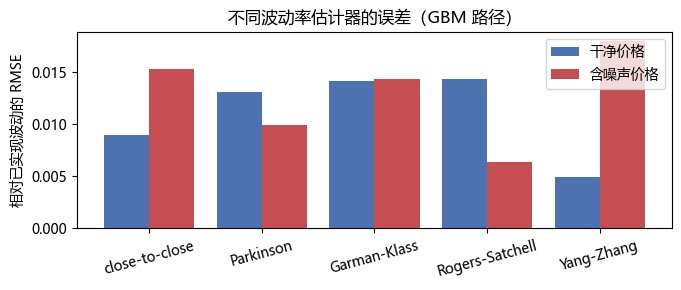

In [3]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(8203)
n_days, n_sim, m = 250, 120, 1440
sigma = 0.20
gap_frac = 0.30
intra_frac = np.sqrt(1.0 - gap_frac ** 2)


def simulate_ohlc(sigma_path, n_sim, n_days, m, rng, jump_prob=0.0, jump_mu=0.0, jump_sd=0.0):
    O = np.zeros((n_sim, n_days))
    H = np.zeros((n_sim, n_days))
    L = np.zeros((n_sim, n_days))
    C = np.zeros((n_sim, n_days))
    rv = np.zeros((n_sim, n_days))
    prev_close = np.full(n_sim, np.log(100.0))
    sigma_2d = np.ndim(sigma_path) == 2
    for t in range(n_days):
        sd = (sigma_path[:, t] if sigma_2d else np.full(n_sim, sigma_path[t])) / np.sqrt(252)
        gap = rng.normal(0.0, gap_frac * sd, n_sim)
        open_log = prev_close + gap
        inc = rng.normal(0.0, intra_frac * sd[:, None] / np.sqrt(m), size=(n_sim, m))
        level = np.cumsum(inc, axis=1)
        if jump_prob > 0:
            has_jump = rng.random(n_sim) < jump_prob
            jump = rng.normal(jump_mu, jump_sd, n_sim) * has_jump
            step = rng.integers(0, m, n_sim)
            level += jump[:, None] * (np.arange(m)[None, :] >= step[:, None])
        path = open_log[:, None] + level
        O[:, t] = open_log
        H[:, t] = np.maximum(path.max(axis=1), open_log)
        L[:, t] = np.minimum(path.min(axis=1), open_log)
        C[:, t] = path[:, -1]
        full = np.column_stack([prev_close, path])
        rv[:, t] = np.sum(np.diff(full, axis=1) ** 2, axis=1)
        prev_close = C[:, t]
    return np.exp(O), np.exp(H), np.exp(L), np.exp(C), rv


def estimators(O, H, L, C):
    r_cc = np.diff(np.log(C), axis=1)
    cc = r_cc.std(axis=1, ddof=1) * np.sqrt(252)
    park = np.sqrt(np.maximum(np.mean(np.log(H / L) ** 2, axis=1) / (4 * np.log(2)), 1e-12) * 252)
    gk_var = 0.5 * np.log(H / L) ** 2 - (2 * np.log(2) - 1) * np.log(C / O) ** 2
    gk = np.sqrt(np.maximum(gk_var.mean(axis=1), 1e-12) * 252)
    rs_var = np.log(H / C) * np.log(H / O) + np.log(L / C) * np.log(L / O)
    rs = np.sqrt(np.maximum(rs_var.mean(axis=1), 1e-12) * 252)
    r_o = np.log(O[:, 1:] / C[:, :-1])
    r_c = np.log(C[:, 1:] / O[:, 1:])
    rs2 = np.mean(np.log(H[:, 1:] / C[:, 1:]) * np.log(H[:, 1:] / O[:, 1:])
                  + np.log(L[:, 1:] / C[:, 1:]) * np.log(L[:, 1:] / O[:, 1:]), axis=1)
    n = r_c.shape[1]
    k = 0.34 / (1.34 + (n + 1) / (n - 1))
    yz = np.sqrt((r_o.var(axis=1, ddof=1) + k * r_c.var(axis=1, ddof=1) + (1 - k) * rs2) * 252)
    return {"close-to-close": cc, "Parkinson": park, "Garman-Klass": gk,
            "Rogers-Satchell": rs, "Yang-Zhang": yz}


sigma_gbm = np.full(n_days, sigma)
O, H, L, C, rv = simulate_ohlc(sigma_gbm, n_sim, n_days, m, rng)
bench = np.sqrt(rv.mean(axis=1) * 252)
print("GBM 基准(已实现)波动均值", round(float(bench.mean()), 4))
est = estimators(O, H, L, C)
for name, val in est.items():
    print(f"  {name}: 均值 {val.mean():.4f} 偏差 {np.mean(val - bench):+.4f} "
          f"RMSE {np.sqrt(np.mean((val - bench) ** 2)):.4f}")

noise = 0.003
On = O * np.exp(rng.normal(0.0, noise, O.shape))
Hn = H * np.exp(rng.normal(0.0, noise, O.shape))
Ln = L * np.exp(rng.normal(0.0, noise, O.shape))
Cn = C * np.exp(rng.normal(0.0, noise, C.shape))
est_noise = estimators(On, Hn, Ln, Cn)
print("加入 0.3% 微观结构噪声后")
for name, val in est_noise.items():
    print(f"  {name}: 均值 {val.mean():.4f} 偏差 {np.mean(val - bench):+.4f} "
          f"RMSE {np.sqrt(np.mean((val - bench) ** 2)):.4f}")

jump_p, jump_mu, jump_sd = 0.03, -0.02, 0.05
O2, H2, L2, C2, rv2 = simulate_ohlc(sigma_gbm, n_sim, n_days, m, rng, jump_p, jump_mu, jump_sd)
bench2 = np.sqrt(rv2.mean(axis=1) * 252)
est2 = estimators(O2, H2, L2, C2)
print("跳跃模型基准波动均值", round(float(bench2.mean()), 4))
for name, val in est2.items():
    print(f"  {name}: 均值 {val.mean():.4f} 偏差 {np.mean(val - bench2):+.4f}")

phi_sv, eta_sv = 0.95, 0.12
log_sig = np.zeros((n_sim, n_days))
log_sig[:, 0] = np.log(sigma)
for t in range(1, n_days):
    log_sig[:, t] = (1 - phi_sv) * np.log(sigma) + phi_sv * log_sig[:, t - 1] + rng.normal(0.0, eta_sv, n_sim)
O3, H3, L3, C3, rv3 = simulate_ohlc(np.exp(log_sig), n_sim, n_days, m, rng)
bench3 = np.sqrt(rv3.mean(axis=1) * 252)
est3 = estimators(O3, H3, L3, C3)
print("随机波动模型基准波动均值", round(float(bench3.mean()), 4))
for name, val in est3.items():
    print(f"  {name}: 均值 {val.mean():.4f} 偏差 {np.mean(val - bench3):+.4f}")

fig, ax = plt.subplots(figsize=(7, 3))
names = list(est.keys())
clean_rmse = [np.sqrt(np.mean((est[k] - bench) ** 2)) for k in names]
noise_rmse = [np.sqrt(np.mean((est_noise[k] - bench) ** 2)) for k in names]
x = np.arange(len(names))
ax.bar(x - 0.2, clean_rmse, width=0.4, label="干净价格", color="#4c72b0")
ax.bar(x + 0.2, noise_rmse, width=0.4, label="含噪声价格", color="#c44e52")
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15)
ax.set_ylabel("相对已实现波动的 RMSE")
ax.set_title("不同波动率估计器的误差（GBM 路径）")
ax.legend()
plt.tight_layout()
plt.show()



**读数**：GBM 路径的基准已实现波动 20.0%。干净价格下：close-to-close 均值 20.04%、RMSE 0.0089；Parkinson 18.75%、RMSE 0.0131；Garman–Klass 18.61%、RMSE 0.0142；Rogers–Satchell 18.61%、RMSE 0.0144；Yang–Zhang 19.62%、RMSE 0.0049，**误差最小**。range 类估计器偏低，是因为它们主要看日内区间，漏掉了 30% 的隔夜跳空方差；Yang–Zhang 把隔夜单独加回来，所以最接近。加入 0.3% 噪声后，close-to-close 被抬高到 21.16%（正偏差），Yang–Zhang 也被抬高到 21.74%——**噪声会系统性地把波动率估高**。

**跳跃模型**：基准 24.41%，close-to-close 24.47% 几乎无偏；但 range 类只有 19.5%–21.1%，因为一次跳跃对日收益方差贡献很大，对日内区间却贡献有限。**随机波动模型**：基准 22.49%，close-to-close 22.62%、Yang–Zhang 22.09% 都接近，range 类仍偏低。

**常见错误**：

1. 只看 close-to-close，浪费日内信息；或只看 Parkinson，漏掉隔夜跳空。
2. 不做噪声/频率敏感性检查。采样频率、买卖价差都会改变估计。
3. 用日频 range 直接除以 252 或乘错年化因子。

**停下来想一想**：为什么 range 类估计器在跳跃模型里偏差最大？

<details><summary>对照你的思路</summary>

range 类估计器（Parkinson、GK、RS）用的是**日内最高最低**，它们假设价格在区间内连续游走。一次跳跃会让日收益方差变大，但最高最低之间的区间并不会同比例变大（跳跃可能发生在收盘附近，或者只是把价格整体平移）。所以 range 低估了跳跃贡献的方差。close-to-close 直接看日收益，反而把跳跃算进去了。

</details>

---

## 3. 波动率的风格事实与预测

### 3.1 四个风格事实

- **聚集（clustering）**：大波动后面跟大波动，小波动后面跟小波动；
- **均值回归**：波动率不会一直在高位或低位，长期会回到中枢；
- **季节性**：月内、周内、假期前后、财报/交割前后有明显规律；
- **与收益/成交量的关系**：下跌时波动率往往上升（杠杆效应），成交量放大常伴随波动放大。

### 3.2 三个预测工具

**EWMA**（指数加权）：

$$\sigma_t^2=\lambda\sigma_{t-1}^2+(1-\lambda)r_{t-1}^2,\qquad \lambda=0.94.$$

**GARCH(1,1)**：

$$\sigma_t^2=\omega+\alpha r_{t-1}^2+\beta\sigma_{t-1}^2,\qquad
\text{长期方差}=\frac{\omega}{1-\alpha-\beta}.$$

**波动率锥**：把历史上不同期限的滚动波动率画成分位数带，看当前波动率处在什么位置。**方差溢价**：隐含方差减已实现方差，长期平均为正——这是卖方收的“保险费”。

### 3.3 代码：GARCH、EWMA、波动率锥与方差溢价



真实长期波动 0.2008


GARCH 估计 omega/alpha/beta [3.0000e-06 7.8092e-02 8.9955e-01]
GARCH 长期年化波动 0.1891 当前 EWMA/GARCH 0.202 0.2145


对未来 20 日波动的预测 RMSE:
  预测器   RMSE
 EWMA 0.0558
GARCH 0.0508
20日滚动 0.0562
波动率锥（历史 1000 日，当前为最后一段）
 horizon    P5   P25   P50   P75   P95  current  pct
       5 0.065 0.114 0.158 0.216 0.349    0.233 81.4
      10 0.089 0.129 0.160 0.214 0.335    0.216 76.1
      20 0.105 0.131 0.163 0.215 0.315    0.202 69.7
      60 0.123 0.140 0.167 0.229 0.313    0.174 53.2
平均 IV 0.2082 平均未来 RV 0.1783
方差溢价(vol 点) 2.98 方差差 0.011811 为正比例 73.4%


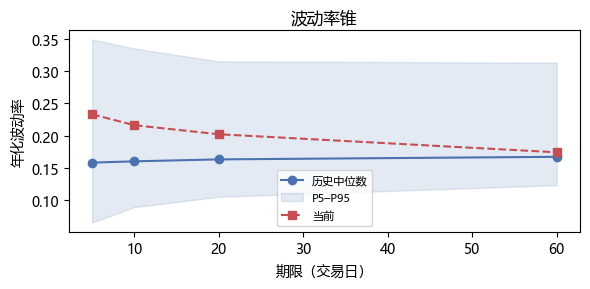

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(8204)
n = 1500
omega_t, alpha_t, beta_t = 3.2e-6, 0.08, 0.90
var = np.zeros(n)
var[0] = omega_t / (1 - alpha_t - beta_t)
z = rng.normal(size=n)
ret = np.zeros(n)
for t in range(n):
    if t > 0:
        var[t] = omega_t + alpha_t * ret[t - 1] ** 2 + beta_t * var[t - 1]
    ret[t] = np.sqrt(var[t]) * z[t]
print("真实长期波动", round(float(np.sqrt(omega_t / (1 - alpha_t - beta_t) * 252)), 4))

lam = 0.94
ewma_var = np.zeros(n)
ewma_var[0] = ret.var()
for t in range(1, n):
    ewma_var[t] = lam * ewma_var[t - 1] + (1 - lam) * ret[t - 1] ** 2
ewma_vol = np.sqrt(ewma_var * 252)


def garch_nll(params):
    omega, alpha, beta = params
    if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 1:
        return 1e10
    var_ = np.empty(n)
    var_[0] = ret.var()
    for t in range(1, n):
        var_[t] = omega + alpha * ret[t - 1] ** 2 + beta * var_[t - 1]
    if np.any(var_ <= 0):
        return 1e10
    return 0.5 * np.sum(np.log(var_) + ret ** 2 / var_)


res = minimize(garch_nll, x0=[1e-6, 0.08, 0.90], method="L-BFGS-B",
               bounds=[(1e-12, 1e-3), (1e-6, 0.5), (0.0, 0.999)])
omega, alpha, beta = res.x
garch_var = np.empty(n)
garch_var[0] = ret.var()
for t in range(1, n):
    garch_var[t] = omega + alpha * ret[t - 1] ** 2 + beta * garch_var[t - 1]
garch_vol = np.sqrt(garch_var * 252)
long_vol = np.sqrt(omega / (1 - alpha - beta) * 252)
print("GARCH 估计 omega/alpha/beta", np.round([omega, alpha, beta], 6))
print("GARCH 长期年化波动", round(float(long_vol), 4),
      "当前 EWMA/GARCH", round(float(ewma_vol[-1]), 4), round(float(garch_vol[-1]), 4))

h_win = 20
rmse_rows = []
for name, fc in [("EWMA", ewma_vol), ("GARCH", garch_vol),
                 ("20日滚动", np.sqrt(pd.Series(ret ** 2).rolling(h_win).mean().values * 252))]:
    errs = []
    for t in range(h_win, n - h_win - 1):
        future = np.std(ret[t + 1:t + h_win + 1], ddof=1) * np.sqrt(252)
        errs.append((fc[t] - future) ** 2)
    rmse_rows.append([name, round(float(np.sqrt(np.mean(errs))), 4)])
print("对未来 20 日波动的预测 RMSE:")
print(pd.DataFrame(rmse_rows, columns=["预测器", "RMSE"]).to_string(index=False))

hist = ret[:1000]
current = ret[1000:]
cone = []
for h in [5, 10, 20, 60]:
    rv = pd.Series(hist).rolling(h).std(ddof=1).dropna().values * np.sqrt(252)
    cur = np.std(current[-h:], ddof=1) * np.sqrt(252)
    pct = np.percentile(rv, [5, 25, 50, 75, 95])
    cone.append([h, *np.round(pct, 3), round(float(cur), 3),
                 round(float((rv < cur).mean() * 100), 1)])
print("波动率锥（历史 1000 日，当前为最后一段）")
print(pd.DataFrame(cone, columns=["horizon", "P5", "P25", "P50", "P75", "P95", "current", "pct"]).to_string(index=False))

iv_syn = 1.15 * ewma_vol
rv_fwd = np.array([np.std(ret[t + 1:t + 21], ddof=1) * np.sqrt(252) for t in range(n - 20)])
vrp = iv_syn[:n - 20] ** 2 - rv_fwd ** 2
print("平均 IV", round(float(iv_syn[:n - 20].mean()), 4),
      "平均未来 RV", round(float(rv_fwd.mean()), 4))
print("方差溢价(vol 点)", round(float(np.mean(iv_syn[:n - 20] - rv_fwd) * 100), 2),
      "方差差", round(float(vrp.mean()), 6), "为正比例", f"{np.mean(vrp > 0):.1%}")

fig, ax = plt.subplots(figsize=(6, 3))
horizons = [c[0] for c in cone]
ax.plot(horizons, [c[3] for c in cone], "o-", color="#4c72b0", label="历史中位数")
ax.fill_between(horizons, [c[1] for c in cone], [c[5] for c in cone],
                color="#4c72b0", alpha=0.15, label="P5–P95")
ax.plot(horizons, [c[6] for c in cone], "s--", color="#c44e52", label="当前")
ax.set_xlabel("期限（交易日）")
ax.set_ylabel("年化波动率")
ax.set_title("波动率锥")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()



**读数**：真实长期波动 20.08%；GARCH 估出 $\omega=3.0\times10^{-6}$、$\alpha=0.0781$、$\beta=0.8995$，长期波动 18.91%（参数恢复得不错）。预测未来 20 日波动的 RMSE：EWMA 5.58、GARCH 5.08、20 日滚动 5.62 个波动率点，**GARCH 略好**。波动率锥显示当前 5 日波动 23.3% 位于历史 81.4% 分位（偏贵），60 日 17.4% 只在 53% 分位。方差溢价：合成 IV 平均 20.82%、未来 RV 平均 17.83%，平均溢价 2.98 个波动率点，73.4% 的时间为正——**买保险的人平均付了钱，卖保险的人平均收了钱**。

**常见错误**：

1. 用 EWMA 的 λ 拍脑袋。λ 越大越平滑、越滞后，要按标的和频率校准。
2. 把 GARCH 的长期波动当“当前波动”。当前波动可能离长期中枢很远。
3. 只看 IV 高低，不看 RV 与波动率锥位置。
4. 把方差溢价当“必胜”。它是平均意义上的，尾部一次大亏可以吃掉很多次小赚。

**停下来想一想**：方差溢价长期为正，为什么不能无脑卖期权？

<details><summary>对照你的思路</summary>

因为溢价是对**尾部风险**的补偿。卖期权收益有限、亏损可能很大；在危机里 RV 会瞬间远超 IV，一次极端行情就能把很多次小赚吐回去。而且卖期权还有保证金、流动性、路径依赖问题。正确的用法是把它当成一种风险溢价，用小仓位、对冲、限额去“收租”，而不是满仓赌它均值回归。

</details>

---

## 4. 隐含波动率的动态：水平、skew、期限结构

### 4.1 三个维度

- **水平**：整体 IV 高低，常用平值 IV 或 VIX 代表；
- **skew/微笑**：同一到期日不同行权价的 IV 形状，股票/商品常见“低行权价更高”；
- **期限结构**：近月与远月 IV 的差，常见 contango（远月高）或 backwardation（近月高）。

### 4.2 skew 的五个来源

1. **信用/杠杆**：公司杠杆越高，股价下跌时越危险，看跌更贵；
2. **真实偏度**：真实收益分布本身左偏（暴跌多于暴涨）；
3. **put 对冲需求**：机构和散户都买看跌保护，推高看跌 IV；
4. **并购/事件 call 需求**：被收购预期推高看涨一侧的 IV；
5. **指数相关性与崩盘风险**：成分股相关性在下跌时上升，指数看跌更贵。

### 4.3 怎么用

- 水平：IV 高/低要结合 RV 与波动率锥判断；
- skew：相对陡/skew 平可以做多空偏斜（risk reversal、蝶式）；
- 期限结构：近远月价差、日历价差、事件前后 IV 变化。

---

## 5. 对冲：ad hoc 与 utility-based

### 5.1 两种思路

- **ad hoc**：按固定频率（每天/每周）或 delta 带（偏离阈值才调）对冲；
- **utility-based**：在“对冲成本 vs 风险”之间做最优化，最大化期望效用。

实务上多数人用 ad hoc + 成本约束：**对冲太勤，成本吃掉收益；对冲太懒，路径风险变大。**

### 5.2 离散对冲的 PnL

连续对冲且无成本时，Delta 中性组合的 PnL 近似为

$$\text{PnL}\approx\frac12\int \Gamma_t S_t^2\left(\sigma_{\text{realized}}^2-\sigma_{\text{implied}}^2\right)dt.$$

离散对冲后，PnL 变成**分布**：依赖路径、依赖实际波动、依赖成本。方向风险被消掉，剩下的是“波动率判断 + 路径运气 + 成本”。

### 5.3 代码：跨式与 Delta 对冲



买入跨式权利金 6.0508


未对冲: 均值 -0.449 标准差 4.834 胜率 37.5%
离散对冲: 均值 -0.423 标准差 1.824 胜率 39.2%
相关(未对冲, RV) 0.256 相关(对冲, RV) 0.911 相关(对冲, IV^2-RV^2) -0.901


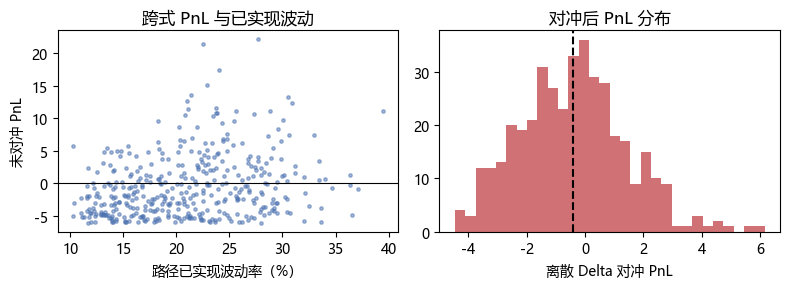

In [5]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(8205)
n_scen, n_days = 400, 30
S0, K, r, iv = 100.0, 100.0, 0.02, 0.22
T0 = 30 / 252
dt = 1 / 252
true_vols = rng.uniform(0.12, 0.30, n_scen)
Z = rng.normal(size=(n_scen, n_days))
inc = (r - 0.5 * true_vols[:, None] ** 2) * dt + true_vols[:, None] * np.sqrt(dt) * Z
path = np.exp(np.column_stack([np.full(n_scen, np.log(S0)),
                               np.log(S0) + np.cumsum(inc, axis=1)]))
premium = bsm(S0, K, T0, r, iv, "C") + bsm(S0, K, T0, r, iv, "P")
print("买入跨式权利金", round(float(premium), 4))


def straddle_value(S_t, T):
    if T <= 0:
        return abs(S_t - K)
    return bsm(S_t, K, T, r, iv, "C") + bsm(S_t, K, T, r, iv, "P")


def straddle_delta(S_t, T):
    if T <= 0:
        return 0.0
    d1 = (np.log(S_t / K) + (r + 0.5 * iv ** 2) * T) / (iv * np.sqrt(T))
    return norm.cdf(d1) - norm.cdf(-d1)


cost = 0.0002
pnl_u, pnl_h, rv = [], [], []
for s in range(n_scen):
    p = path[s]
    pnl_u.append(abs(p[-1] - K) - premium)
    hedge, pnl = 0.0, 0.0
    prev_opt, prev_S = straddle_value(p[0], T0), p[0]
    for t in range(1, n_days + 1):
        T = T0 - t * dt
        S_t = p[t]
        pnl += hedge * (S_t - prev_S)
        opt = straddle_value(S_t, T)
        pnl += opt - prev_opt
        new_hedge = -straddle_delta(S_t, T)
        pnl -= abs(new_hedge - hedge) * S_t * cost
        hedge, prev_opt, prev_S = new_hedge, opt, S_t
    pnl_h.append(pnl)
    rv.append(np.std(np.diff(np.log(p)), ddof=1) * np.sqrt(252))
pnl_u = np.array(pnl_u)
pnl_h = np.array(pnl_h)
rv = np.array(rv)
print("未对冲: 均值", round(float(pnl_u.mean()), 3), "标准差",
      round(float(pnl_u.std(ddof=1)), 3), "胜率", f"{np.mean(pnl_u > 0):.1%}")
print("离散对冲: 均值", round(float(pnl_h.mean()), 3), "标准差",
      round(float(pnl_h.std(ddof=1)), 3), "胜率", f"{np.mean(pnl_h > 0):.1%}")
print("相关(未对冲, RV)", round(float(np.corrcoef(pnl_u, rv)[0, 1]), 3),
      "相关(对冲, RV)", round(float(np.corrcoef(pnl_h, rv)[0, 1]), 3),
      "相关(对冲, IV^2-RV^2)", round(float(np.corrcoef(pnl_h, iv ** 2 - rv ** 2)[0, 1]), 3))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].scatter(rv * 100, pnl_u, s=6, alpha=0.5, color="#4c72b0")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("路径已实现波动率（%）")
axes[0].set_ylabel("未对冲 PnL")
axes[0].set_title("跨式 PnL 与已实现波动")
axes[1].hist(pnl_h, bins=30, color="#c44e52", alpha=0.8)
axes[1].axvline(float(pnl_h.mean()), color="black", linestyle="--")
axes[1].set_xlabel("离散 Delta 对冲 PnL")
axes[1].set_title("对冲后 PnL 分布")
plt.tight_layout()
plt.show()



**读数**：跨式权利金 6.0508；400 条路径的真实波动率在 12%–30% 之间随机。不 hedge 时，PnL 均值 −0.449、标准差 4.834，胜率 37.5%；每天 delta 对冲（2bp 成本）后，均值 −0.423，**标准差从 4.83 降到 1.82**，胜率 39.2%。对冲后 PnL 与路径 RV 的相关 0.911、与 $IV^2-RV^2$ 的相关 −0.901——**delta 对冲把“方向赌注”变成了“波动率赌注”**，而且路径依赖仍然存在（同样的 RV，PnL 不是同一个数）。

**常见错误**：

1. 以为 delta 中性就没有风险。Gamma、Vega、Theta 都还在。
2. 忽略对冲成本。高频对冲在低波动率下会把利润吃光。
3. 用一条路径的 PnL 评价策略。要看分布、胜率、尾部。
4. 用 IV 22% 的模型价去给 12% 真实波动的路径定价，却忘了自己收的是 22% 的保险费。

**停下来想一想**：为什么对冲后标准差下降，但均值几乎没变？

<details><summary>对照你的思路</summary>

因为 delta 对冲消掉的是“方向暴露”带来的大头方差，均值由“付的保险费”和“预期赔付”决定，不受对冲频率影响（忽略成本）。对冲后剩下的方差来自波动率判断错误（真实 RV 与 IV 的差）和离散/路径误差。所以对冲让 PnL 更“纯”，但不会让一个负期望的交易变成正期望。

</details>

---

## 6. 资金管理与交易评价

### 6.1 Kelly 与破产风险

Kelly 比例（连续近似）：

$$f^*=\frac{\mu}{\sigma^2}.$$

本例 $\mu=0.8\%$/月、$\sigma=4\%$/月，$f^*=0.008/0.04^2=5$——5 倍杠杆。满 Kelly 的长期增长最快，但回撤和破产风险也最大；实务上常用 1/4–1/2 Kelly。**参数误估最危险**：把 $\mu$ 高估一点、$\sigma$ 低估一点，$f^*$ 会被放大很多倍。

### 6.2 评价指标

| 指标 | 公式（简述） | 看什么 |
|---|---|---|
| Sharpe | 平均收益 / 收益标准差 | 单位波动的收益 |
| Sortino | 平均收益 / 下行标准差 | 只惩罚下跌波动 |
| Calmar | 年化收益 / 最大回撤 | 收益与回撤比 |
| K-ratio | 对数净值趋势的 t 值 | 净值曲线平滑度 |
| Omega | 高于阈值的收益和 / 低于阈值的损失和 | 收益分布形状 |

**持续性**：过去的 Sharpe 对未来的预测力通常很弱。策略可能只是运气好，或者环境变了。

### 6.3 代码：Kelly、破产概率与评价



Kelly 比例 f* = mu/sigma^2 = 5.0
 f/f*   f  期末中位数  5%分位  平均最大回撤  破产概率
  0.2 1.0   2.32  1.12   -0.07 0.00%
  0.4 2.0   4.49  1.03   -0.14 0.10%
  0.6 3.0   7.85  0.88   -0.21 0.30%
  0.8 4.0  10.44  0.53   -0.28 0.90%
  1.0 5.0  12.02  0.23   -0.35 4.50%
样本路径评价: Sharpe 1.03 Sortino 1.84 Calmar 0.94 K 比率(趋势 t 值) 44.4 Omega 2.14 最大回撤 -43.1%
100 个策略前后半段 Sharpe 的秩相关 0.176


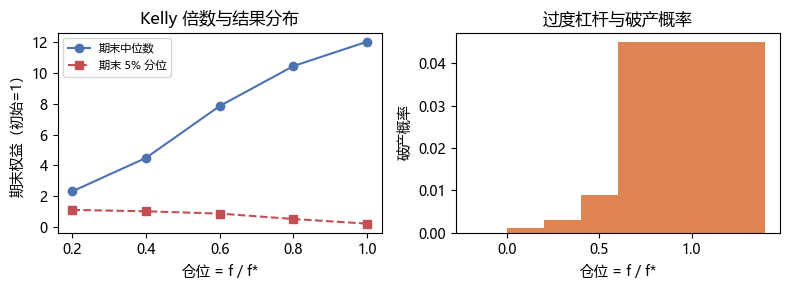

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(8206)
mu_m, sigma_m = 0.008, 0.04
kelly = mu_m / sigma_m ** 2
n_months, n_sim = 120, 2000
print("Kelly 比例 f* = mu/sigma^2 =", round(float(kelly), 2))
rows = []
for mult in [0.2, 0.4, 0.6, 0.8, 1.0]:
    f = mult * kelly
    r = rng.normal(mu_m, sigma_m, size=(n_sim, n_months))
    equity = np.cumprod(1 + f * r, axis=1)
    peak = np.maximum.accumulate(equity, axis=1)
    mdd = (equity / peak - 1).mean()
    ruin = np.mean(equity[:, -1] < 0.2)
    rows.append([mult, round(f, 2), round(float(np.median(equity[:, -1])), 2),
                 round(float(np.percentile(equity[:, -1], 5)), 2), round(float(mdd), 2),
                 f"{ruin:.2%}"])
print(pd.DataFrame(rows, columns=["f/f*", "f", "期末中位数", "5%分位", "平均最大回撤", "破产概率"]).to_string(index=False))

r_sample = rng.normal(mu_m, sigma_m, n_months)
strat = 0.5 * kelly * r_sample
equity_curve = np.cumprod(1 + strat)
lr = np.log(equity_curve)
t_idx = np.arange(n_months)
slope, intercept = np.polyfit(t_idx, lr, 1)
resid = lr - (slope * t_idx + intercept)
se_slope = np.sqrt(np.sum(resid ** 2) / (n_months - 2) / np.sum((t_idx - t_idx.mean()) ** 2))
sharpe = strat.mean() / strat.std(ddof=1) * np.sqrt(12)
downside = strat[strat < 0]
sortino = strat.mean() / downside.std(ddof=1) * np.sqrt(12)
peak = np.maximum.accumulate(equity_curve)
mdd_s = (equity_curve / peak - 1).min()
calmar = (strat.mean() * 12) / abs(mdd_s)
omega = strat[strat > 0].sum() / abs(strat[strat < 0].sum())
print("样本路径评价: Sharpe", round(float(sharpe), 2), "Sortino", round(float(sortino), 2),
      "Calmar", round(float(calmar), 2), "K 比率(趋势 t 值)", round(float(slope / se_slope), 2),
      "Omega", round(float(omega), 2), "最大回撤", f"{mdd_s:.1%}")

n_strat, n_ret = 100, 120
first, second = [], []
for _ in range(n_strat):
    rr = rng.normal(mu_m, sigma_m, n_ret)
    first.append(rr[:60].mean() / rr[:60].std(ddof=1))
    second.append(rr[60:].mean() / rr[60:].std(ddof=1))
first = np.array(first)
second = np.array(second)
rank_corr = pd.Series(first).corr(pd.Series(second), method="spearman")
print("100 个策略前后半段 Sharpe 的秩相关", round(float(rank_corr), 3))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
mults = [row[0] for row in rows]
axes[0].plot(mults, [row[2] for row in rows], "o-", color="#4c72b0", label="期末中位数")
axes[0].plot(mults, [row[3] for row in rows], "s--", color="#c44e52", label="期末 5% 分位")
axes[0].set_xlabel("仓位 = f / f*")
axes[0].set_ylabel("期末权益（初始=1）")
axes[0].set_title("Kelly 倍数与结果分布")
axes[0].legend(fontsize=8)
axes[1].bar(mults, [float(row[5].strip('%')) / 100 for row in rows], color="#dd8452")
axes[1].set_xlabel("仓位 = f / f*")
axes[1].set_ylabel("破产概率")
axes[1].set_title("过度杠杆与破产概率")
plt.tight_layout()
plt.show()



**读数**：Kelly 比例 $f^*=5$。仓位从 0.2 倍 Kelly 加到 1 倍 Kelly：期末中位数从 2.32 升到 12.02，但 5% 分位从 1.12 掉到 0.23，平均最大回撤从 −7% 扩大到 −35%，**破产概率从 0% 升到 4.5%**。样本路径评价：Sharpe 1.03、Sortino 1.84、Calmar 0.94、K 比率 44.4、Omega 2.14、最大回撤 −43.1%。100 个策略前后半段 Sharpe 的秩相关只有 0.176——**过去的业绩排名，对未来的预测力很弱**。

**常见错误**：

1. 满 Kelly。参数稍错就会被放大，回撤和破产风险陡增。
2. 把 K 比率、Calmar 单指标当结论。它们奖励低波动、低杠杆，也可能掩盖尾部。
3. 用样本内最优参数评价策略。要留样本外。
4. 忽略“策略容量/拥挤”：人多的地方，波动率交易的溢价会被压薄。

**停下来想一想**：为什么“降低仓位”反而可能提高长期效用？

<details><summary>对照你的思路</summary>

Kelly 最大化的是长期对数增长，但它假设参数已知、收益独立同分布。现实中 $\mu$、$\sigma$ 都会估错，且尾部比正态更厚；过度下注会让“坏路径”直接出局（破产或被迫减仓），失去复利机会。降低到 1/2 或 1/4 Kelly，牺牲一点期望增长，换来更小的回撤和更低的破产概率，长期看更稳。

</details>

---

## 7. 其他：心理、VIX 与交易生命周期

### 7.1 心理偏差（简）

- **过度自信**：高估自己的预测能力，仓位过大；
- **损失厌恶**：亏损时不肯止损，赚一点就跑；
- **锚定**：盯着买入价、历史 IV 不放；
- **近因偏差**：最近几次大赚就以为波动率溢价永远在。

Sinclair 强调：交易系统要**预设规则**，把“情绪决策”变成“流程决策”。

### 7.2 VIX、VIX 期货与杠杆 ETF

- **VIX** 是标普 500 期权的隐含波动率指数，用一篮子期权价格合成；
- **VIX 期货** 有期限结构，可交易 contango/backwardation；
- **VIX ETN** 通常持有 VIX 期货，展期成本高，长期持有会被 contango 磨损；
- **杠杆 ETF** 每日再平衡，波动越大、路径越差，长期收益会被“波动衰减”。
- **方差互换/离散度**：方差互换直接交易“已实现方差 vs 隐含方差”；离散度（dispersion）用指数期权对成分股期权，赌的是相关性/相对波动。两者都是相对价值，容量、执行与保证金要求高，个人先用期权组合模拟，不要直接上复杂结构。

### 7.3 一笔交易的完整生命周期

1. **pre-trade**：观点（RV 会高于/低于 IV）、工具（期权/跨式/方差）、期限、仓位、对冲方案、最大亏损；
2. **交易中**：建仓成本、对冲频率、风险限额、事件检查；
3. **post-trade**：PnL 归因（方向/Gamma/Vega/Theta/成本）、与预期对比、记录教训；
4. **复盘**：是判断错了，还是执行/成本/运气问题？

---

## 本章小结

### 一张表

| 主题 | 公式/做法 | 用途 |
|---|---|---|
| BSM | $C=S\Phi(d_1)-Ke^{-rT}\Phi(d_2)$ | 价格↔波动率翻译 |
| IV | 反解使模型价=市场价 | 跨行权价比较 |
| close-to-close | $\sqrt{252/(N-1)\sum(r-\bar r)^2}$ | 简单、无偏、噪声大 |
| Parkinson | $\overline{\ln(H/L)^2}/(4\ln2)$ | 用日内区间 |
| Garman–Klass | $0.5\overline{h^2}-(2\ln2-1)\overline{\ln(C/O)^2}$ | 加入开收盘 |
| Rogers–Satchell | 对漂移不敏感 | 趋势市场 |
| Yang–Zhang | 隔夜+日内+RS 加权 | 股票/含跳空 |
| EWMA | $\lambda\sigma^2+(1-\lambda)r^2$ | 短期预测 |
| GARCH | $\omega+\alpha r^2+\beta\sigma^2$ | 聚集+均值回归 |
| 方差溢价 | $IV^2-RV^2$ | 保险费 |
| Kelly | $f^*=\mu/\sigma^2$ | 仓位上限 |
| 离散对冲 PnL | $\frac12\int\Gamma S^2(\sigma_R^2-\sigma_I^2)dt$ | 波动率赌注 |

### 八句话

1. 模型是翻译工具，不是真理。
2. 交易波动率，不是交易方向。
3. 估计器各有偏差：range 类漏隔夜，close-to-close 怕噪声。
4. 波动率会聚集、会均值回归，预测要用 EWMA/GARCH/锥。
5. IV 平均高于 RV，是保险费，不是免费午餐。
6. skew 有五个来源，别只把它当“市场情绪”。
7. 对冲消掉方向，留下 Gamma/Vega/Theta 和成本。
8. 仓位比预测更重要：活着才能复利。

---

## 本章习题

**1.** 用 BSM 的假设说明：为什么“波动率恒定”这一条在真实市场几乎肯定不成立？它给定价带来什么后果？

**2.** 某天 $H=105$、$L=98$，用 Parkinson 公式算这一天的日均方差和年化波动（取 $4\ln2\approx2.7726$）。

**3.** 为什么 range 类估计器在跳跃模型里低估波动率？Yang–Zhang 为什么能缓解隔夜跳空问题？

**4.** 写出 EWMA 和 GARCH(1,1) 的递推式，并说明两者在“波动率聚集”上的区别。

**5.** 近月 IV 18%、远月 IV 22%，总方差分别是多少？区间远期方差是多少（期限分别为 0.25、0.5 年）？

**6.** 买入跨式，权利金 6.05；到期标的价格 96 或 104。分别求 PnL（忽略成本），并说明为什么 IV 22% 但真实 RV 只有 12% 时可能亏钱。

**7.** Kelly 比例 $f^*=5$，若把 $\mu$ 从 0.8% 高估到 1.2%、$\sigma$ 仍为 4%，新的 $f^*$ 是多少？这说明什么？

**8.** 一个策略 Sharpe 1.0、最大回撤 40%、Omega 2.0。为什么不能只看 Sharpe？应该补充看什么？

<details><summary>参考答案</summary>

**1.** 真实波动率会随宏观、事件、流动性变化，且存在跳跃与厚尾。后果：BSM 价格只能作为“基准/语言”，不同行权价、不同期限要用不同 IV（微笑/期限结构）来修正；直接拿一个 σ 给所有期权定价会系统性错误。

**2.** $h=\ln(105/98)=0.0690$，$h^2=0.00476$；日均方差 $0.00476/2.7726=0.00172$；年化波动 $\sqrt{0.00172\times252}=\sqrt{0.4328}\approx65.8\%$。

**3.** 跳跃对日收益方差的贡献大，但对日内最高最低区间贡献有限；range 类只看到区间，低估跳跃方差。Yang–Zhang 把隔夜收益单独加进方差，弥补了“隔夜跳空不被日内 range 捕捉”的问题。

**4.** EWMA：$\sigma_t^2=\lambda\sigma_{t-1}^2+(1-\lambda)r_{t-1}^2$；GARCH：$\sigma_t^2=\omega+\alpha r_{t-1}^2+\beta\sigma_{t-1}^2$。EWMA 是 GARCH 在 $\omega=0$、$\alpha+\beta=1$ 时的特例；GARCH 有长期均值 $\omega/(1-\alpha-\beta)$，会均值回归。

**5.** $w_1=0.18^2\times0.25=0.0081$，$w_2=0.22^2\times0.5=0.0242$；区间方差 $(0.0242-0.0081)/(0.5-0.25)=0.0644$，区间年化波动约 25.4%。

**6.** 到期 96：支付 $|96-100|=4$，PnL $=4-6.05=-2.05$；到期 104：支付 4，PnL $=-2.05$。若真实 RV 只有 12%，跨式到期大多只动很小，支付经常小于权利金；你付的是 22% 的保险费，收的是 12% 的波动，平均亏钱。

**7.** $f^*=1.2\%/4\%^2=1.2\%/0.0016=7.5$。说明参数误估会显著放大仓位：μ 高估 50%，仓位从 5 倍变 7.5 倍；若同时低估 σ，杠杆更夸张，破产风险上升。

**8.** Sharpe 只看收益/波动，不看回撤、尾部、路径和成本；40% 回撤对多数人不可承受，且可能触发强平。应补充最大回撤/Calmar、尾部亏损、胜率/盈亏比、成本后收益、容量与样本外表现。

</details>

---

## 参考资料

- Sinclair, E. *Volatility Trading* (2nd ed.). Wiley, 2013.（本书原书）
- Black, F. & Scholes, M. (1973). The Pricing of Options and Corporate Liabilities.
- Merton, R. C. (1973). Theory of Rational Option Pricing.
- Parkinson, M. (1980). The Extreme Value Method for Estimating the Variance of the Rate of Return.
- Garman, M. B. & Klass, M. J. (1980). On the Estimation of Security Price Volatilities from Historical Data.
- Rogers, L. C. G. & Satchell, S. E. (1991). Estimating Variance from High, Low and Closing Prices.
- Yang, D. & Zhang, Q. (2000). Drift-Independent Volatility Estimation Based on High, Low, Open, and Close Prices.
- Bollerslev, T. (1986). Generalized Autoregressive Conditional Heteroskedasticity.
- Kelly, J. L. (1956). A New Interpretation of Information Rate.
